# Prognose der Tagesmitteltemperatur in Berlin

Dieses Notebook trainiert ein einfaches KI-Modell auf den DWD-Tageswerten der Station **Berlin-Dahlem (FU), 00403**. Ziel ist die Prognose der Tagesmitteltemperatur für den nächsten Tag.

Die verwendete CSV reicht vom 01.01.2020 bis 01.11.2026. Das Notebook lädt die Datei eigenständig; es benötigt also keine zuvor ausgeführten Zellen aus einem anderen Notebook.

## 1. Prognoseaufgabe und Datengrundlage

Wir vergleichen zwei Modelle für dieselbe Aufgabe: Sie sollen die Tagesmitteltemperatur am nächsten Tag schätzen. **Modell A** nutzt die Tagesmitteltemperaturen der fünf Vortage und den Tag im Jahr. **Modell B** erhält zusätzlich Tagesminimum, Tagesmaximum, Sonnenscheindauer und Niederschlag für jeden der fünf Vortage.

Beide Modelle sagen denselben Zielwert voraus und werden mit derselben chronologischen Aufteilung und denselben Trainings- und Testtagen geprüft. Ein Beispiel: Für Dienstag verwendet das Modell die Wetterwerte von Donnerstag bis Montag. Es werden nur Tage verwendet, für die alle benötigten Eingabewerte vorhanden sind.

In [19]:
import calendar
import csv
from datetime import date, timedelta
from pathlib import Path

csv_pfad = Path("berlin_dwd_tageswerte_2020_bis_2026-11-01.csv")
with csv_pfad.open(encoding="utf-8", newline="") as datei:
    wetterdaten = list(csv.DictReader(datei))

print(f"Geladene Tageszeilen: {len(wetterdaten)}")
print(f"Zeitraum: {wetterdaten[0]['datum']} bis {wetterdaten[-1]['datum']}")
print("Zielspalte: temp_durchschnitt_c (°C)")

Geladene Tageszeilen: 2497
Zeitraum: 2020-01-01 bis 2026-11-01
Zielspalte: temp_durchschnitt_c (°C)


## 2. Trainingsdaten und Eingangsmerkmale

Jedes Beispiel hat denselben Zielwert: die gemessene Tagesmitteltemperatur des Zieltags. Modell A hat **sechs Eingaben**: fünf Tagesmitteltemperaturen (`t-5` bis `t-1`) und den Kalendertag. Modell B hat **26 Eingaben**: für jeden der fünf Vortage jeweils Tagesminimum, Tagesmaximum, Tagesmitteltemperatur, Sonnenscheindauer und Niederschlagsmenge, dazu ebenfalls den Kalendertag.

Der Kalendertag hilft, die Jahreszeit zu berücksichtigen. Schaltjahre werden auf die Skala 1–365 abgebildet; der 29. Februar erhält den Zwischenwert 59,5. Trainingsbeispiele mit fehlendem Zielwert, fehlenden Eingabewerten oder nicht aufeinanderfolgenden Tagen werden ausgelassen. Dadurch können beide Modelle auf exakt denselben Beispielen verglichen werden.

In [28]:
feature_names = [
    "temp_t_minus_5",
    "temp_t_minus_4",
    "temp_t_minus_3",
    "temp_t_minus_2",
    "temp_t_minus_1",
    "tag_im_jahr",
]
wetter_merkmale = [
    "temp_min_c",
    "temp_max_c",
    "temp_durchschnitt_c",
    "sonnenstunden",
    "niederschlagsmenge_mm",
]
feature_names_erweitert = [
    f"{merkmal}_t_minus_{versatz}"
    for versatz in range(5, 0, -1)
    for merkmal in wetter_merkmale
] + ["tag_im_jahr"]

def tag_im_jahr_365(datum):
    tag = datum.timetuple().tm_yday
    if calendar.isleap(datum.year):
        if datum.month == 2 and datum.day == 29:
            return 59.5
        if datum.month > 2:
            return tag - 1
    return tag

trainingsbeispiele = []
for index in range(5, len(wetterdaten)):
    zielzeile = wetterdaten[index]
    ziel_datum = date.fromisoformat(zielzeile["datum"])
    vergangene_zeilen = wetterdaten[index - 5:index]
    erwartete_vortage = [ziel_datum - timedelta(days=versatz) for versatz in range(5, 0, -1)]
    tatsaechliche_vortage = [date.fromisoformat(zeile["datum"]) for zeile in vergangene_zeilen]

    if tatsaechliche_vortage != erwartete_vortage:
        continue
    if not zielzeile["temp_durchschnitt_c"]:
        continue
    if any(not zeile[merkmal] for zeile in vergangene_zeilen for merkmal in wetter_merkmale):
        continue

    beispiel = {
        "datum": zielzeile["datum"],
        "tag_im_jahr": tag_im_jahr_365(ziel_datum),
        "ziel_temp_c": float(zielzeile["temp_durchschnitt_c"]),
    }
    for versatz, zeile in zip(range(5, 0, -1), vergangene_zeilen):
        beispiel[f"temp_t_minus_{versatz}"] = float(zeile["temp_durchschnitt_c"])
        for merkmal in wetter_merkmale:
            beispiel[f"{merkmal}_t_minus_{versatz}"] = float(zeile[merkmal])
    trainingsbeispiele.append(beispiel)

print(f"Gemeinsame Trainingsbeispiele: {len(trainingsbeispiele)}")
print(f"Modell A: {len(feature_names)} Eingaben")
print(f"Modell B: {len(feature_names_erweitert)} Eingaben")
print("Beispiel mit erweitertem Merkmalsatz:")
print({merkmal: trainingsbeispiele[0][merkmal] for merkmal in feature_names_erweitert})

Gemeinsame Trainingsbeispiele: 2471
Modell A: 6 Eingaben
Modell B: 26 Eingaben
Beispiel mit erweitertem Merkmalsatz:
{'temp_min_c_t_minus_5': -2.8, 'temp_max_c_t_minus_5': 5.0, 'temp_durchschnitt_c_t_minus_5': 1.8, 'sonnenstunden_t_minus_5': 2.9, 'niederschlagsmenge_mm_t_minus_5': 0.0, 'temp_min_c_t_minus_4': -4.1, 'temp_max_c_t_minus_4': 6.2, 'temp_durchschnitt_c_t_minus_4': -0.3, 'sonnenstunden_t_minus_4': 7.5, 'niederschlagsmenge_mm_t_minus_4': 0.0, 'temp_min_c_t_minus_3': 0.8, 'temp_max_c_t_minus_3': 6.9, 'temp_durchschnitt_c_t_minus_3': 4.3, 'sonnenstunden_t_minus_3': 0.0, 'niederschlagsmenge_mm_t_minus_3': 4.4, 'temp_min_c_t_minus_2': 1.7, 'temp_max_c_t_minus_2': 5.6, 'temp_durchschnitt_c_t_minus_2': 4.1, 'sonnenstunden_t_minus_2': 0.0, 'niederschlagsmenge_mm_t_minus_2': 3.0, 'temp_min_c_t_minus_1': -1.4, 'temp_max_c_t_minus_1': 3.6, 'temp_durchschnitt_c_t_minus_1': 1.4, 'sonnenstunden_t_minus_1': 2.1, 'niederschlagsmenge_mm_t_minus_1': 0.0, 'tag_im_jahr': 6}


## 3. Zeitlich trainieren und testen

Wir trainieren mit Zielterminen von 2020 bis einschließlich 2023 und testen auf den späteren Daten ab 2024. Ein zufälliger Split wäre ungeeignet, weil dabei Zukunftstage im Training landen könnten.

Im Test wird jeweils ein Tag vorhergesagt, und die fünf tatsächlich gemessenen Vortage dienen als Eingabe. Das misst eine **rollierende Ein-Tages-Prognose**. Es testet nicht, wie gut das Modell mehrere Tage ohne neue Messwerte vorausplant.

In [29]:
trainingsdaten = [beispiel for beispiel in trainingsbeispiele if beispiel["datum"] < "2024-01-01"]
testdaten = [beispiel for beispiel in trainingsbeispiele if beispiel["datum"] >= "2024-01-01"]

X_train = [[beispiel[merkmal] for merkmal in feature_names] for beispiel in trainingsdaten]
y_train = [beispiel["ziel_temp_c"] for beispiel in trainingsdaten]
X_test = [[beispiel[merkmal] for merkmal in feature_names] for beispiel in testdaten]
y_test = [beispiel["ziel_temp_c"] for beispiel in testdaten]
X_train_erweitert = [[beispiel[merkmal] for merkmal in feature_names_erweitert] for beispiel in trainingsdaten]
X_test_erweitert = [[beispiel[merkmal] for merkmal in feature_names_erweitert] for beispiel in testdaten]

print(f"Gemeinsames Training: {len(trainingsdaten)} Beispiele, {trainingsdaten[0]['datum']} bis {trainingsdaten[-1]['datum']}")
print(f"Gemeinsamer Test: {len(testdaten)} Beispiele, {testdaten[0]['datum']} bis {testdaten[-1]['datum']}")
print(f"Eingaben pro Beispiel: Modell A {len(feature_names)}, Modell B {len(feature_names_erweitert)}")

Gemeinsames Training: 1456 Beispiele, 2020-01-06 bis 2023-12-31
Gemeinsamer Test: 1015 Beispiele, 2024-01-01 bis 2026-11-01
Eingaben pro Beispiel: Modell A 6, Modell B 26


## 4. Zwei Random Forests trainieren und bewerten

Wir vergleichen zwei Random-Forest-Modelle mit denselben Einstellungen: Modell A verwendet nur die fünf Tagesmitteltemperaturen und den Kalendertag; Modell B verwendet zusätzlich Minimum, Maximum, Sonnenscheindauer und Niederschlag der fünf Vortage. Beide trainieren auf denselben Tagen und werden auf denselben späteren Tagen getestet.

Als einfache Referenz dient die **Persistenz-Baseline**: Sie sagt für jeden Testtag den letzten bekannten Tagesmittelwert voraus (`t-1`). MAE und RMSE messen den Fehler in °C; je kleiner, desto besser. R² beschreibt, wie viel Streuung das Modell im Test erklärt, und ist keine Trefferquote in Prozent.

In [30]:
from html import escape as html_escape
from IPython.display import HTML, display
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score


def zeige_ergebnistabelle(spalten, zeilen):
    zellenstil = "padding: 6px 10px; border-bottom: 1px solid #ccc; text-align: left;"
    kopf = "".join(f"<th style='{zellenstil}'>{html_escape(str(spalte))}</th>" for spalte in spalten)
    koerper = "".join(
        "<tr>" + "".join(f"<td style='{zellenstil}'>{html_escape(str(wert))}</td>" for wert in zeile) + "</tr>"
        for zeile in zeilen
    )
    display(HTML(f"<table style='border-collapse: collapse; margin: 8px 0;'><thead><tr>{kopf}</tr></thead><tbody>{koerper}</tbody></table>"))


def erstelle_random_forest():
    return RandomForestRegressor(
        n_estimators=300,
        min_samples_leaf=3,
        random_state=42,
        n_jobs=-1,
    )


modell = erstelle_random_forest()
modell.fit(X_train, y_train)
vorhersage_test = modell.predict(X_test)

modell_erweitert = erstelle_random_forest()
modell_erweitert.fit(X_train_erweitert, y_train)
vorhersage_test_erweitert = modell_erweitert.predict(X_test_erweitert)

baseline_test = [beispiel["temp_t_minus_1"] for beispiel in testdaten]

mae_modell = mean_absolute_error(y_test, vorhersage_test)
rmse_modell = mean_squared_error(y_test, vorhersage_test) ** 0.5
r2_modell = r2_score(y_test, vorhersage_test)
mae_modell_erweitert = mean_absolute_error(y_test, vorhersage_test_erweitert)
rmse_modell_erweitert = mean_squared_error(y_test, vorhersage_test_erweitert) ** 0.5
r2_modell_erweitert = r2_score(y_test, vorhersage_test_erweitert)
mae_baseline = mean_absolute_error(y_test, baseline_test)
rmse_baseline = mean_squared_error(y_test, baseline_test) ** 0.5
r2_baseline = r2_score(y_test, baseline_test)

print(f"Gemeinsamer Testzeitraum: {testdaten[0]['datum']} bis {testdaten[-1]['datum']} ({len(testdaten)} Tage)")
zeige_ergebnistabelle(
    ["Verfahren", "Eingaben", "MAE (°C)", "RMSE (°C)", "R²"],
    [
        ["Random Forest: Temperatur", len(feature_names), f"{mae_modell:.2f}", f"{rmse_modell:.2f}", f"{r2_modell:.3f}"],
        ["Random Forest: alle Wetterwerte", len(feature_names_erweitert), f"{mae_modell_erweitert:.2f}", f"{rmse_modell_erweitert:.2f}", f"{r2_modell_erweitert:.3f}"],
        ["Persistenz-Baseline", "1", f"{mae_baseline:.2f}", f"{rmse_baseline:.2f}", f"{r2_baseline:.3f}"],
    ],
)

Gemeinsamer Testzeitraum: 2024-01-01 bis 2026-11-01 (1015 Tage)


Verfahren,Eingaben,MAE (°C),RMSE (°C),R²
Random Forest: Temperatur,6,1.75,2.20,0.912
Random Forest: alle Wetterwerte,26,1.62,2.06,0.923
Persistenz-Baseline,1,1.74,2.23,0.909


## 5. Vorhersagen grafisch prüfen

Das erste Diagramm legt die gemessene Temperatur, die Random-Forest-Vorhersage und die Persistenz-Baseline über den Testzeitraum. Im zweiten Diagramm vergleichen wir den mittleren absoluten Fehler (MAE) pro Monat. So sieht man, ob die Fehler im Jahresverlauf variieren und welches Verfahren jeweils näher an den Messwerten liegt.

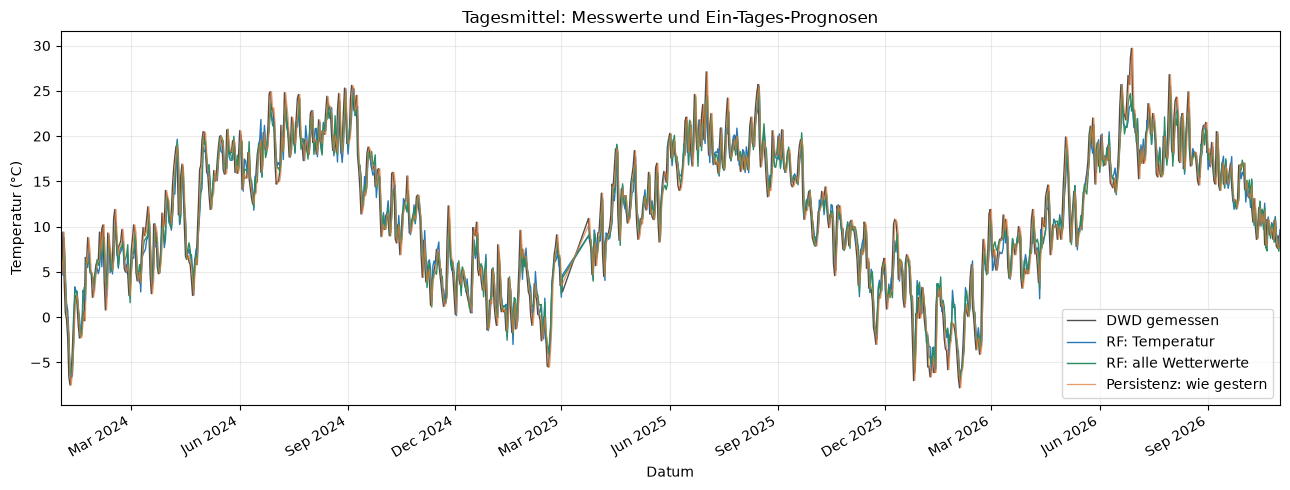

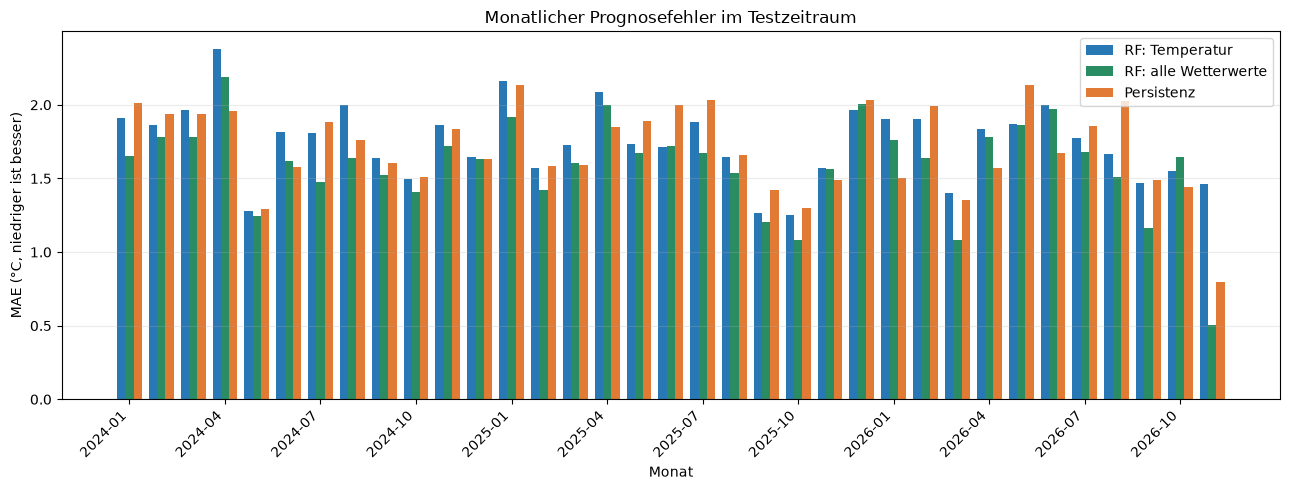

In [31]:
from datetime import datetime
import matplotlib.dates as mdates
import matplotlib.pyplot as plt

test_daten = [datetime.fromisoformat(beispiel["datum"]) for beispiel in testdaten]
fig, ax = plt.subplots(figsize=(13, 5))
ax.plot(test_daten, y_test, label="DWD gemessen", color="#222222", linewidth=1.0, alpha=0.8)
ax.plot(test_daten, vorhersage_test, label="RF: Temperatur", color="#2878B5", linewidth=1.0)
ax.plot(test_daten, vorhersage_test_erweitert, label="RF: alle Wetterwerte", color="#2A8C63", linewidth=1.0)
ax.plot(test_daten, baseline_test, label="Persistenz: wie gestern", color="#E07A35", linewidth=0.9, alpha=0.75)
ax.set_title("Tagesmittel: Messwerte und Ein-Tages-Prognosen")
ax.set_xlabel("Datum")
ax.set_ylabel("Temperatur (°C)")
ax.xaxis.set_major_locator(mdates.MonthLocator(interval=3))
ax.xaxis.set_major_formatter(mdates.DateFormatter("%b %Y"))
ax.set_xlim(test_daten[0], test_daten[-1])
ax.grid(True, alpha=0.25)
ax.legend()
fig.autofmt_xdate()
fig.tight_layout()
plt.show()

monatsgruppen = {}
for index, beispiel in enumerate(testdaten):
    monatsgruppen.setdefault(beispiel["datum"][:7], []).append(index)

monate_test = sorted(monatsgruppen)
mae_modell_monat = []
mae_modell_erweitert_monat = []
mae_baseline_monat = []
for monat in monate_test:
    indices = monatsgruppen[monat]
    mae_modell_monat.append(
        sum(abs(y_test[index] - vorhersage_test[index]) for index in indices) / len(indices)
    )
    mae_modell_erweitert_monat.append(
        sum(abs(y_test[index] - vorhersage_test_erweitert[index]) for index in indices) / len(indices)
    )
    mae_baseline_monat.append(
        sum(abs(y_test[index] - baseline_test[index]) for index in indices) / len(indices)
    )

positionen = list(range(len(monate_test)))
breite = 0.26
fig, ax = plt.subplots(figsize=(13, 5))
ax.bar([position - breite for position in positionen], mae_modell_monat, breite, label="RF: Temperatur", color="#2878B5")
ax.bar(positionen, mae_modell_erweitert_monat, breite, label="RF: alle Wetterwerte", color="#2A8C63")
ax.bar([position + breite for position in positionen], mae_baseline_monat, breite, label="Persistenz", color="#E07A35")
ax.set_title("Monatlicher Prognosefehler im Testzeitraum")
ax.set_xlabel("Monat")
ax.set_ylabel("MAE (°C, niedriger ist besser)")
tick_positionen = positionen[::3]
ax.set_xticks(tick_positionen, [monate_test[position] for position in tick_positionen], rotation=45, ha="right")
ax.grid(axis="y", alpha=0.25)
ax.legend()
fig.tight_layout()
plt.show()

### Ergebnis interpretieren

Ein MAE von beispielsweise 1,75 °C bedeutet, dass die Vorhersage im Mittel etwa 1,75 °C vom gemessenen Tagesmittel abweicht. Der Vergleich mit der Baseline ist wichtig: Ein komplexeres KI-Modell ist nur dann nützlich, wenn es eine einfache Regel zuverlässig übertrifft. Die Testkennzahlen beziehen sich ausschließlich auf die zurückgehaltenen Daten ab 2024.

## 6. Nächsten Tag mit beiden Modellen prognostizieren

Nach dem Test trainieren wir beide Modelle erneut mit allen verfügbaren gemeinsamen Trainingsbeispielen. Sie erhalten dieselben fünf letzten Tage; Modell A verwendet nur die Tagesmitteltemperatur, Modell B alle fünf Wettervariablen. Beide Prognosen werden nebeneinander ausgegeben.

Die Prognose hängt vom letzten Datum in der CSV ab. Wenn du die CSV später mit neueren DWD-Daten aktualisierst, berechnet diese Zelle automatisch den Folgetag. Es handelt sich um experimentelle Ein-Tages-Schätzungen, nicht um eine amtliche Wettervorhersage.

In [32]:
X_alle = [[beispiel[merkmal] for merkmal in feature_names] for beispiel in trainingsbeispiele]
X_alle_erweitert = [[beispiel[merkmal] for merkmal in feature_names_erweitert] for beispiel in trainingsbeispiele]
y_alle = [beispiel["ziel_temp_c"] for beispiel in trainingsbeispiele]

finales_modell = RandomForestRegressor(
    n_estimators=300,
    min_samples_leaf=3,
    random_state=42,
    n_jobs=-1,
)
finales_modell.fit(X_alle, y_alle)

finales_modell_erweitert = RandomForestRegressor(
    n_estimators=300,
    min_samples_leaf=3,
    random_state=42,
    n_jobs=-1,
)
finales_modell_erweitert.fit(X_alle_erweitert, y_alle)

letztes_datum = date.fromisoformat(wetterdaten[-1]["datum"])
prognose_datum = letztes_datum + timedelta(days=1)
letzte_fuenf_zeilen = wetterdaten[-5:]
if any(any(not zeile[merkmal] for merkmal in wetter_merkmale) for zeile in letzte_fuenf_zeilen):
    raise ValueError("Für die Prognose müssen die fünf letzten Tageswerte aller Wettermerkmale vorhanden sein.")

letzte_fuenf_temperaturen = [float(zeile["temp_durchschnitt_c"]) for zeile in letzte_fuenf_zeilen]
merkmale_fuer_prognose = letzte_fuenf_temperaturen + [tag_im_jahr_365(prognose_datum)]
merkmale_fuer_prognose_erweitert = [
    float(zeile[merkmal])
    for zeile in letzte_fuenf_zeilen
    for merkmal in wetter_merkmale
]
merkmale_fuer_prognose_erweitert.append(tag_im_jahr_365(prognose_datum))

prognose_temp_c = finales_modell.predict([merkmale_fuer_prognose])[0]
prognose_temp_erweitert_c = finales_modell_erweitert.predict([merkmale_fuer_prognose_erweitert])[0]

prognosezeilen = [
    [f"Messwert t-{5 - index}", zeile["datum"], f"{temperatur:.1f}", ""]
    for index, (zeile, temperatur) in enumerate(zip(letzte_fuenf_zeilen, letzte_fuenf_temperaturen))
]
prognosezeilen.extend(
    [
        ["Prognose: Temperaturmodell", prognose_datum.isoformat(), f"{prognose_temp_c:.1f}", f"{tag_im_jahr_365(prognose_datum):g}"],
        ["Prognose: alle Wetterwerte", prognose_datum.isoformat(), f"{prognose_temp_erweitert_c:.1f}", f"{tag_im_jahr_365(prognose_datum):g}"],
    ]
)
print(f"Letzter DWD-Messwert: {letztes_datum.isoformat()}")
zeige_ergebnistabelle(
    ["Rolle", "Datum", "Tagesmittel (°C)", "Tag im Jahr"],
    prognosezeilen,
)

Letzter DWD-Messwert: 2026-11-01


Rolle,Datum,Tagesmittel (°C),Tag im Jahr
Messwert t-5,2026-10-28,8.8,
Messwert t-4,2026-10-29,7.8,
Messwert t-3,2026-10-30,7.6,
Messwert t-2,2026-10-31,9.0,
Messwert t-1,2026-11-01,8.2,
Prognose: Temperaturmodell,2026-11-02,8.9,306
Prognose: alle Wetterwerte,2026-11-02,8.3,306
